# Four-receiver CSI: EDA, preprocessing and CNN training

Session `20261104T081805521126Z` contains four real receiver streams and one transmitter. This notebook reviews the executed experiment. All signal exploration is restricted to training attempts; complete scenario groups stay in one partition. The report documents the within-participant/session limits.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

FOLDER = Path.cwd()
if FOLDER.name != "05_four_rx_cnn":
    FOLDER = FOLDER / "notebooks/05_four_rx_cnn"
RESULTS = FOLDER / "results/four_rx_v1"
RERUN = False
if RERUN:
    rerun = FOLDER / "artifacts/notebook_rerun"
    subprocess.run([sys.executable, str(FOLDER / "run.py"), "--output", str(rerun)], check=True)
    RESULTS = FOLDER / "results/notebook_rerun"

def read_json(name):
    return json.loads((RESULTS / name).read_text())

def show_figure(name, width=1100):
    display(Image(filename=str(RESULTS / "figures" / name), width=width))

config = read_json("manifest.json")["config"]
display(pd.Series(config, name="Predefined configuration"))

session_path           ../../data/raw/sessions/20261104T081805521126Z
receivers                                    [rx-1, rx-2, rx-3, rx-4]
window_seconds                                                    4.0
offsets_seconds                         [-0.5, -0.25, 0.0, 0.25, 0.5]
bin_hz                                                             25
lag_seconds                                                       0.1
smoothing_bins                                                      3
minimum_coverage                                                  0.7
split_seed                                                   20261104
training_seeds                                           [17, 29, 43]
max_epochs                                                         40
patience                                                            8
batch_size                                                         16
learning_rate                                                   0.001
weight_decay        

## Inventory, grouping and quality

The split holds out activity/direction scenarios, including both repetitions. Invalid/rejected attempts are excluded before grouping; coverage exclusions cannot redraw membership. The quality rule requires at least 70% finite phase-change time/tone support in every receiver at every configured offset.

total_attempts                                                     255
status_counts          {'accepted': 232, 'invalid': 22, 'rejected': 1}
retained_attempts                                                  206
scenarios                                                          112
participants                                                [khaelano]
offset_count                                                         5
receivers                                     [rx-1, rx-2, rx-3, rx-4]
center_quality       {'rx-1': {'median_records_s': 99.0, 'minimum_c...
policy               Signal plots/statistics restricted to training...
dtype: object

,label,test,train,validation
0,walk_to_fall,4,15,5
1,sit_to_fall,3,14,4
2,stand_to_fall,5,16,6
3,walk_to_sit,5,19,5
4,sit_to_walk,5,20,6
5,sit_to_stand,4,18,6
6,walk_to_stand,2,3,2
7,stand_to_walk,2,4,2
8,stand_to_sit,6,19,6


,eligible,retained,excluded
target,,,
0,144,134,10
1,88,72,16


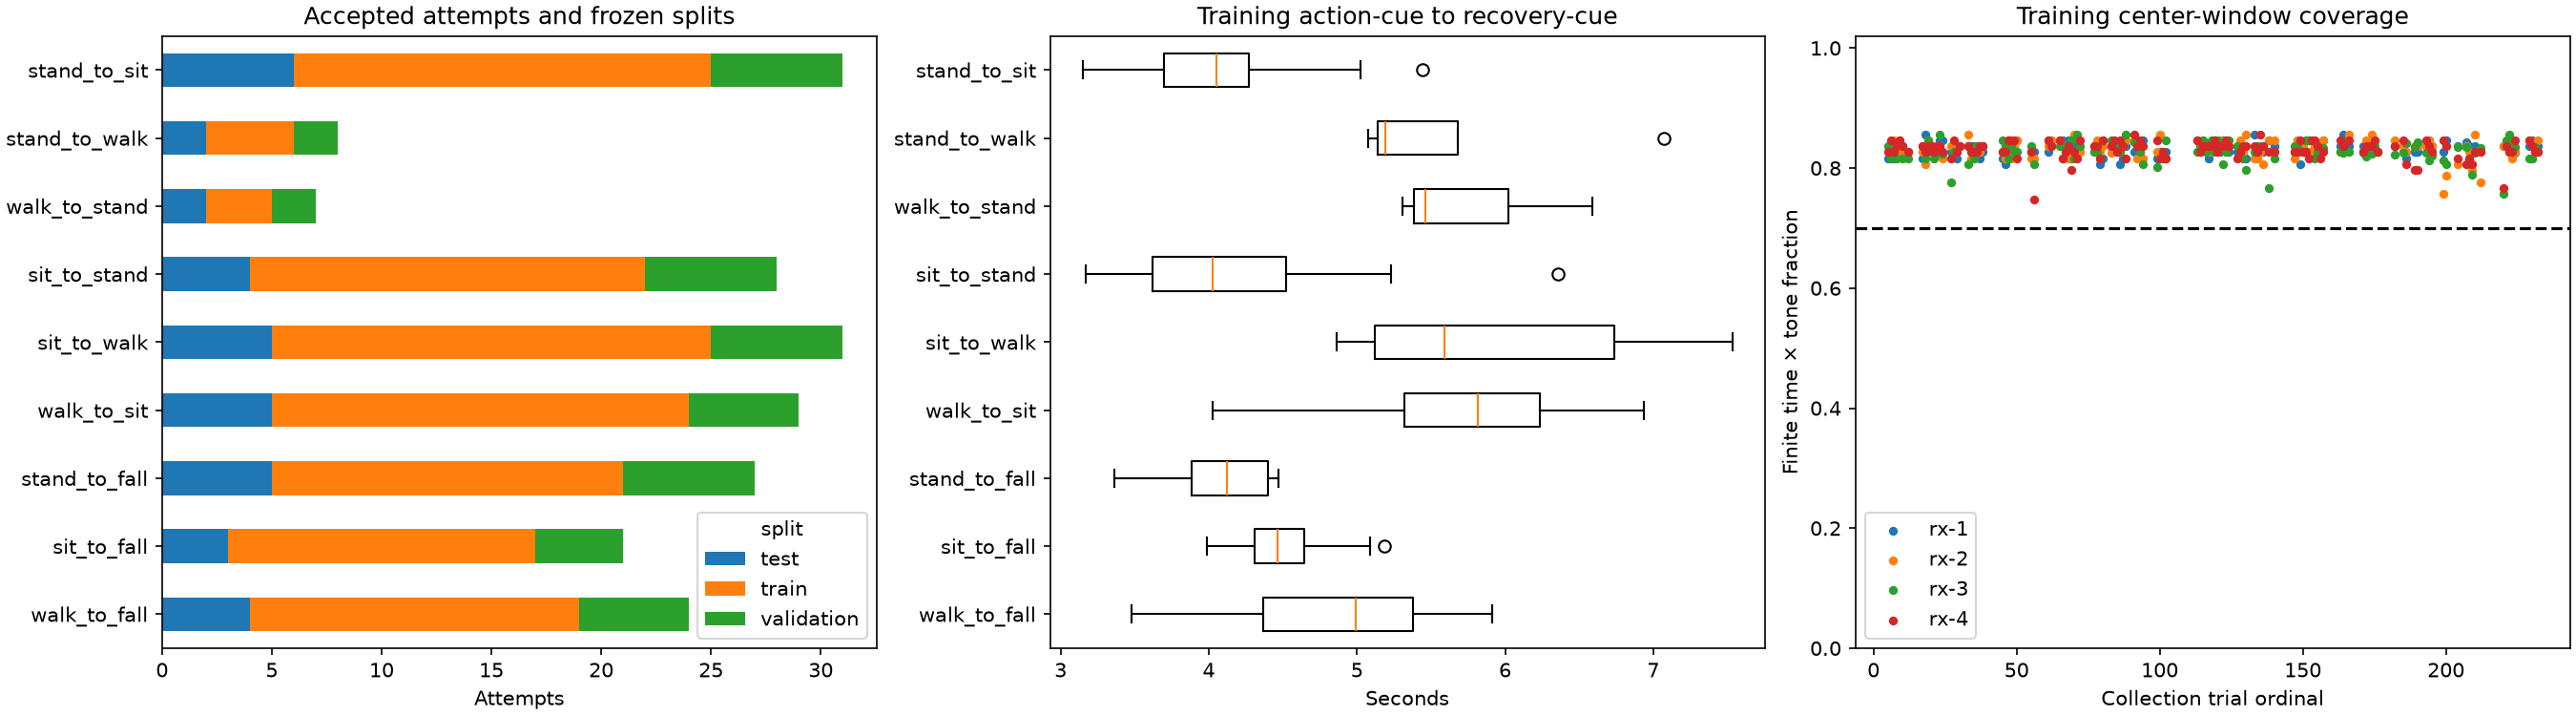

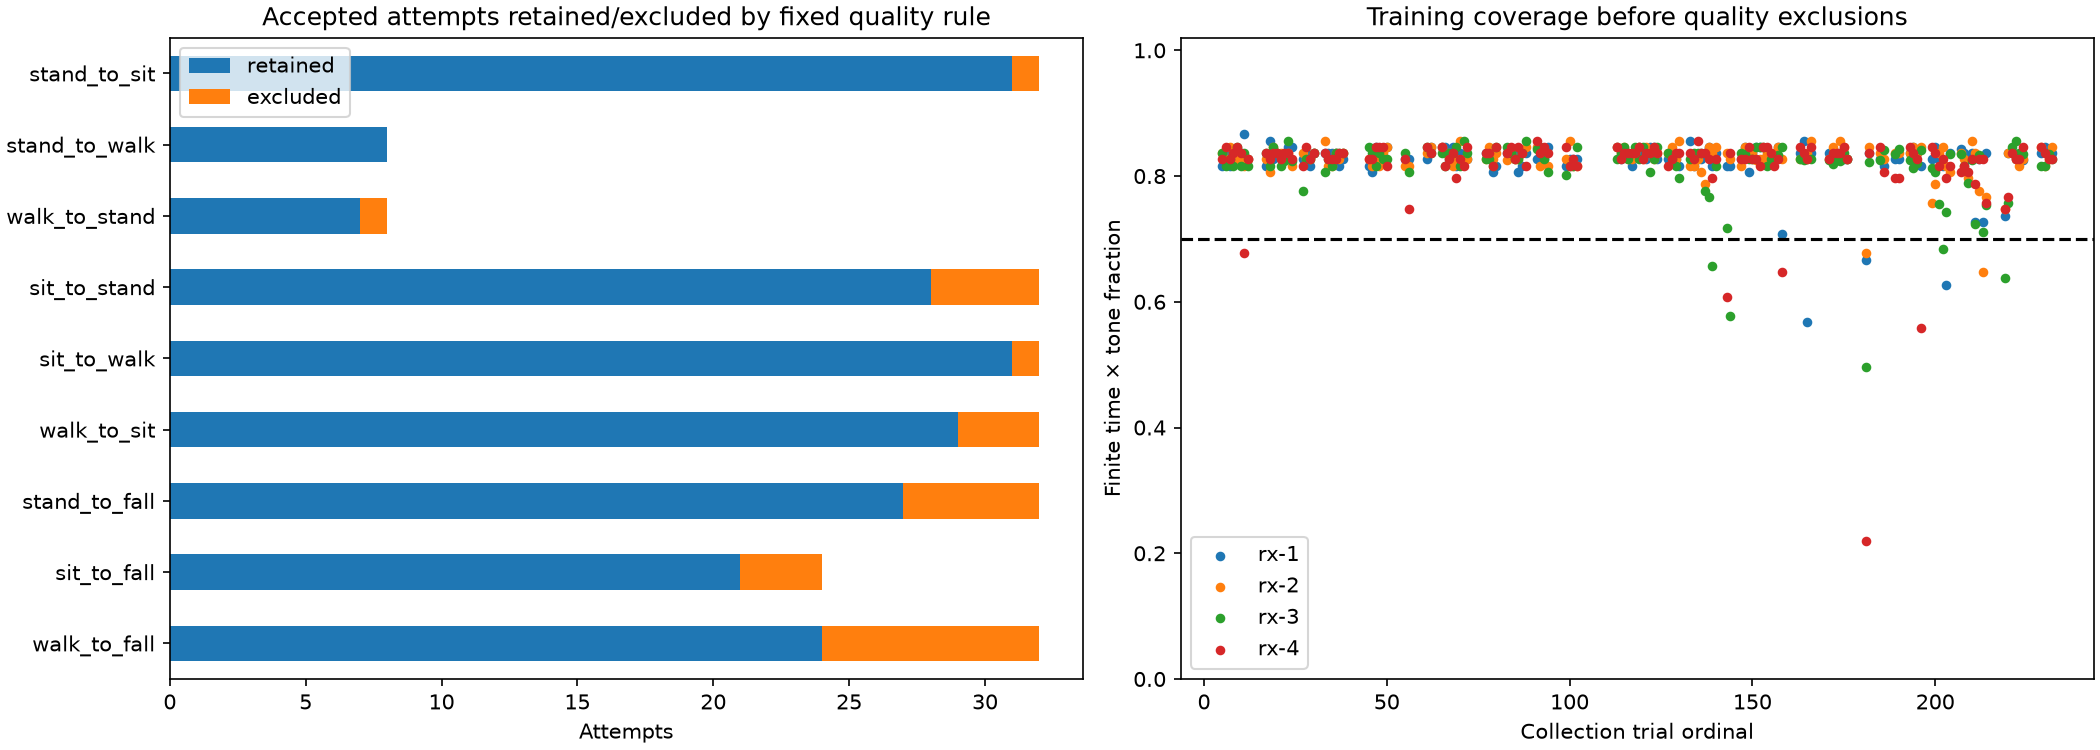

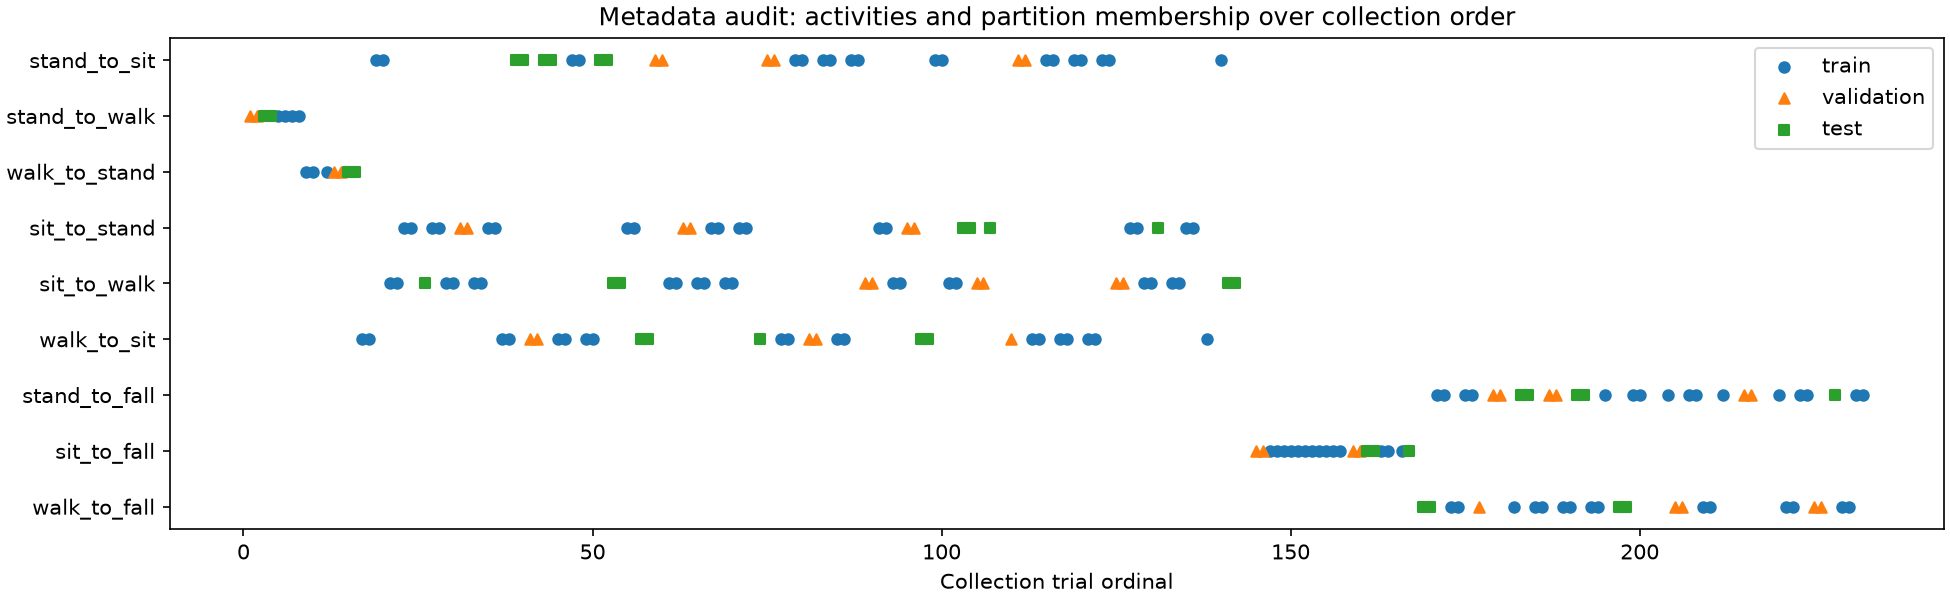

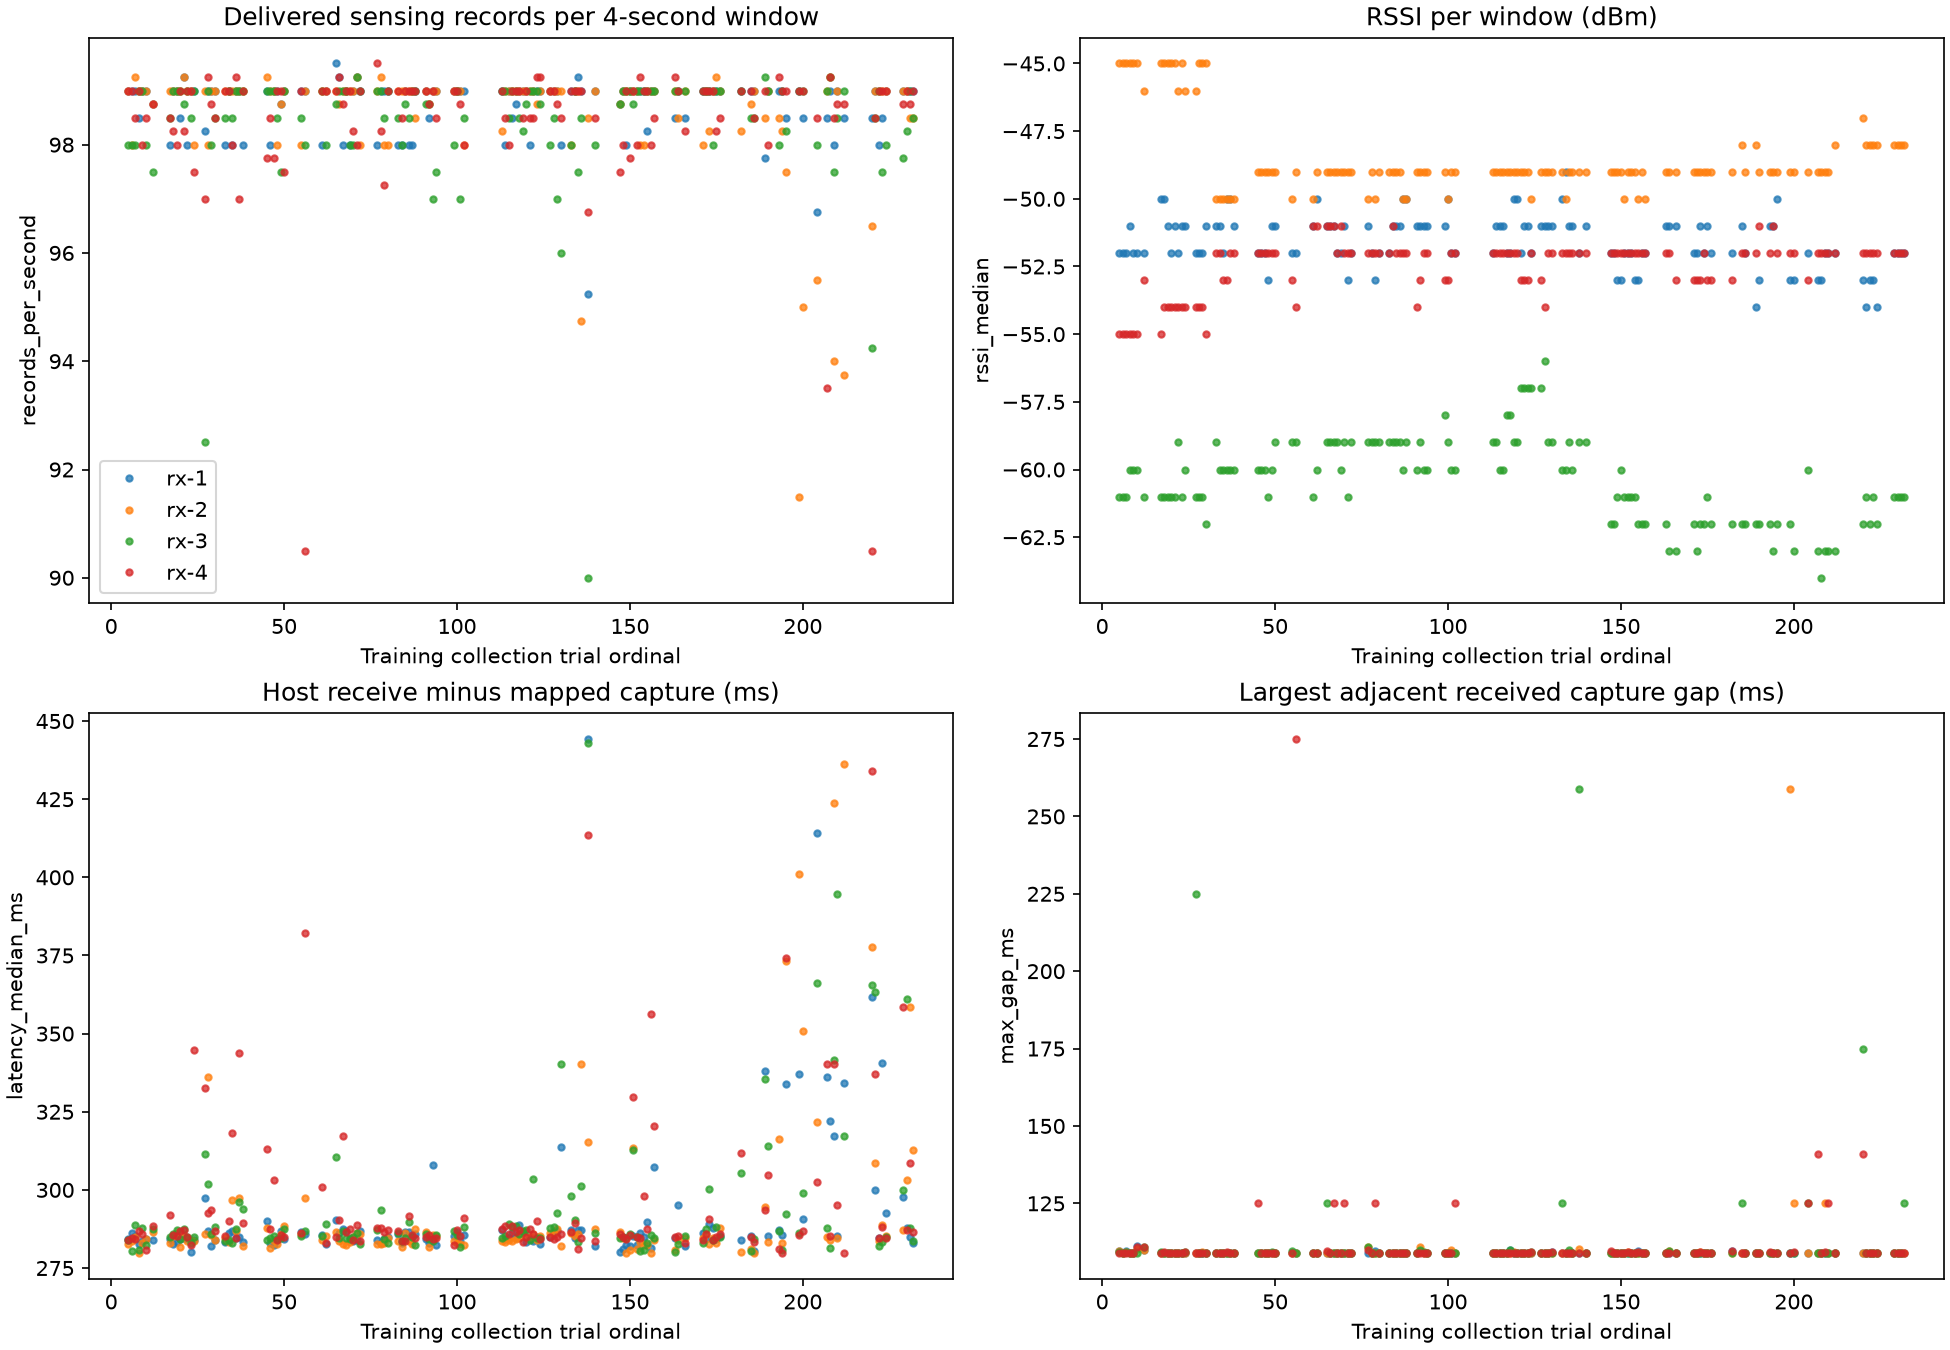

In [2]:
display(pd.Series(read_json("eda_summary.json")))
display(pd.read_csv(RESULTS / "split_counts.csv"))
display(pd.read_csv(RESULTS / "quality_attrition.csv").groupby("target")[["eligible", "retained", "excluded"]].sum())
show_figure("eda_inventory.png")
show_figure("eda_quality_attrition.png")
show_figure("eda_collection_order.png")
show_figure("eda_transport.png")

## Capture-time preprocessing and signal EDA

Gateway sidecars align mapped transmitter enqueue timestamps with the operator timeline. Host delivery time is never substituted. Canonical decoding and explicit driver-state masking retain 242 physical tones. Inputs use 25 Hz bins, explicit masks, and no gap interpolation. Phase is binned as sine/cosine. Normalization fits training windows only. The following plots use training attempts; galleries select the first training attempt per activity without ranking its signal.

,label,receiver,offset_seconds,attempts,median_records_s,median_coverage,min_coverage,median_rssi,median_latency_ms,max_gap_ms,bad_driver_packets
0,sit_to_fall,rx-1,-0.50,14,99.000,0.836529,0.816612,-52.0,283.695359,109.458765,2.0
1,sit_to_fall,rx-1,-0.25,14,99.000,0.836529,0.816612,-52.0,284.916596,109.458765,2.0
2,sit_to_fall,rx-1,0.00,14,99.000,0.836405,0.806653,-52.0,283.457675,109.458765,1.0
3,sit_to_fall,rx-1,0.25,14,99.000,0.836529,0.816281,-52.0,285.086143,109.458765,1.0
4,sit_to_fall,rx-1,0.50,14,99.000,0.826570,0.806653,-52.0,282.718479,109.458765,1.0
5,sit_to_fall,rx-2,-0.50,14,99.000,0.836467,0.816322,-49.0,281.765095,109.254804,0.0
6,sit_to_fall,rx-2,-0.25,14,99.000,0.836529,0.826529,-49.0,284.436315,109.458019,0.0
7,sit_to_fall,rx-2,0.00,14,99.000,0.836508,0.816612,-49.0,282.835783,109.458019,0.0
8,sit_to_fall,rx-2,0.25,14,99.000,0.836467,0.806653,-49.0,284.217844,109.458019,0.0
9,sit_to_fall,rx-2,0.50,14,99.000,0.836529,0.816322,-49.0,284.212953,109.458019,0.0


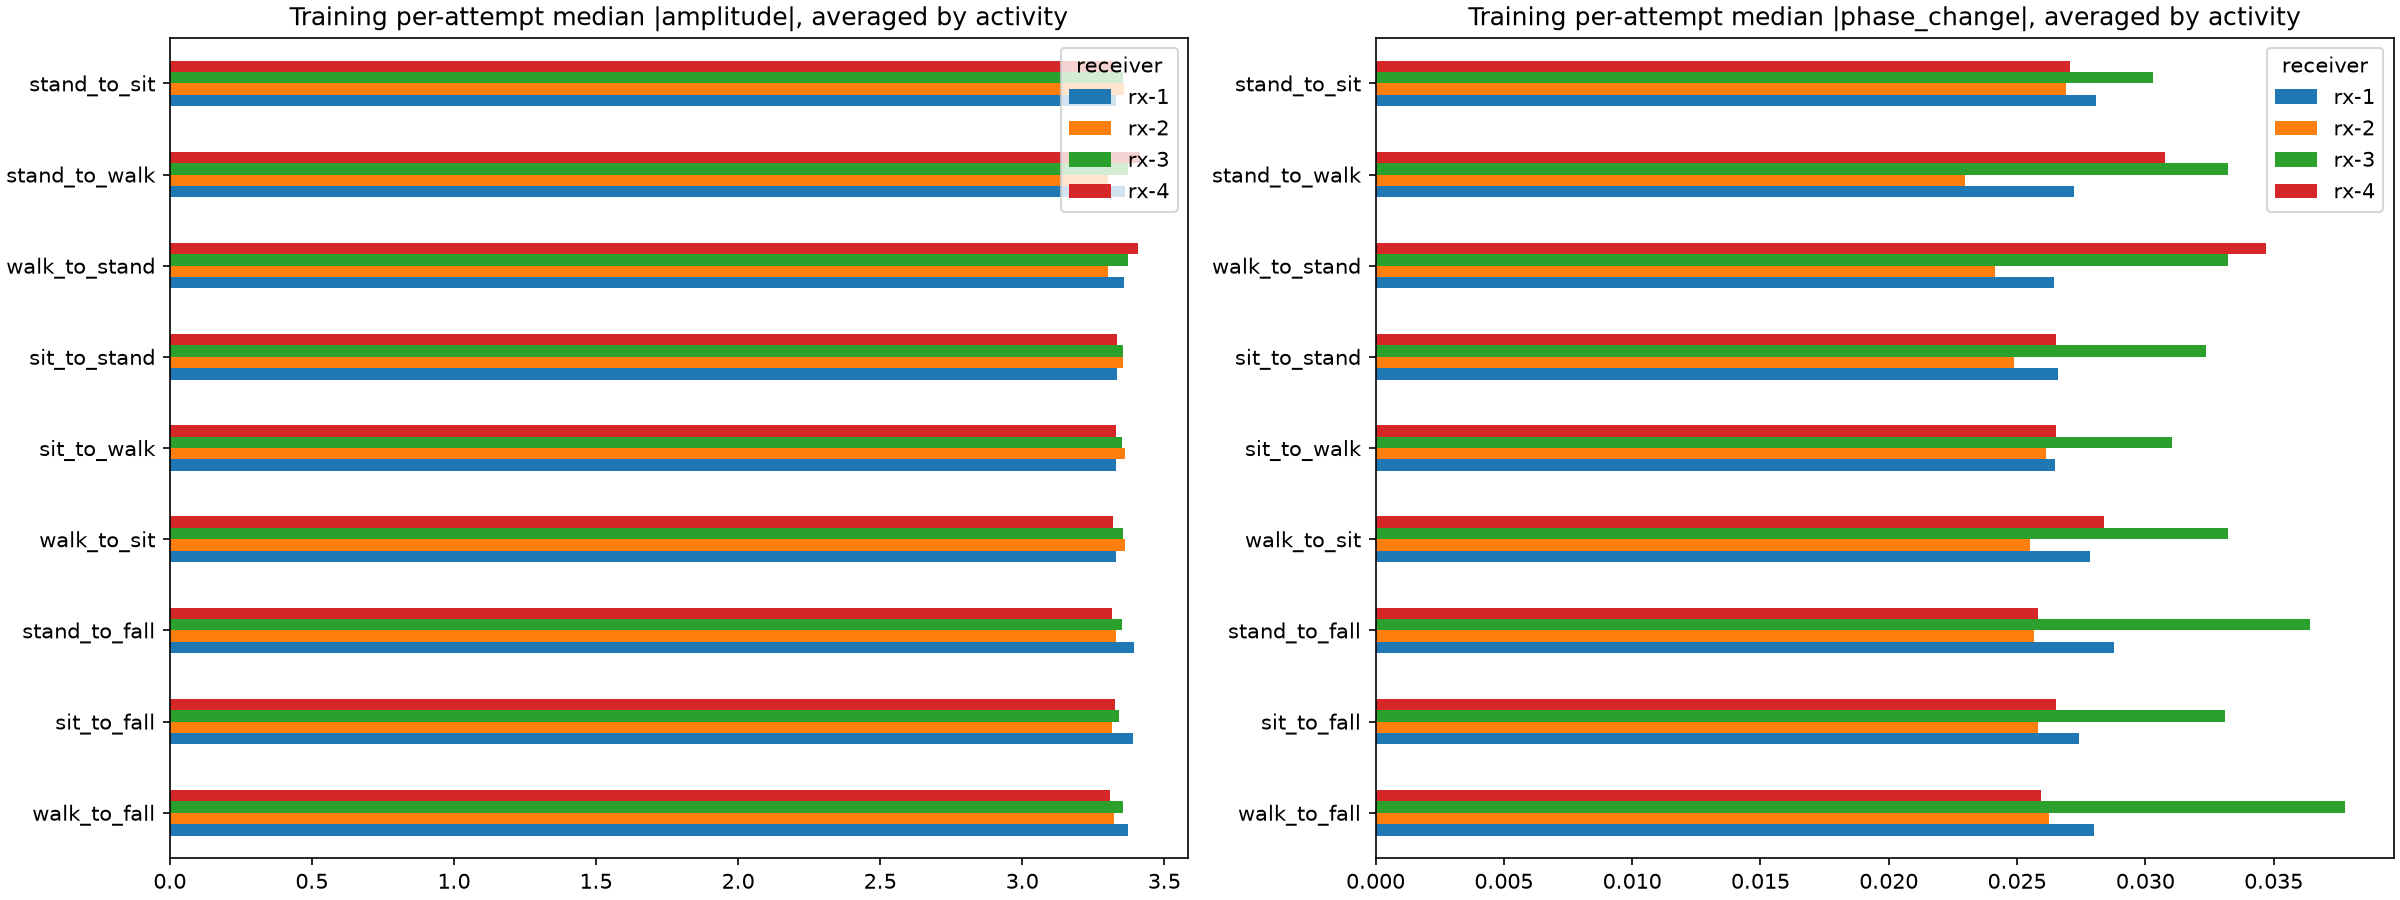

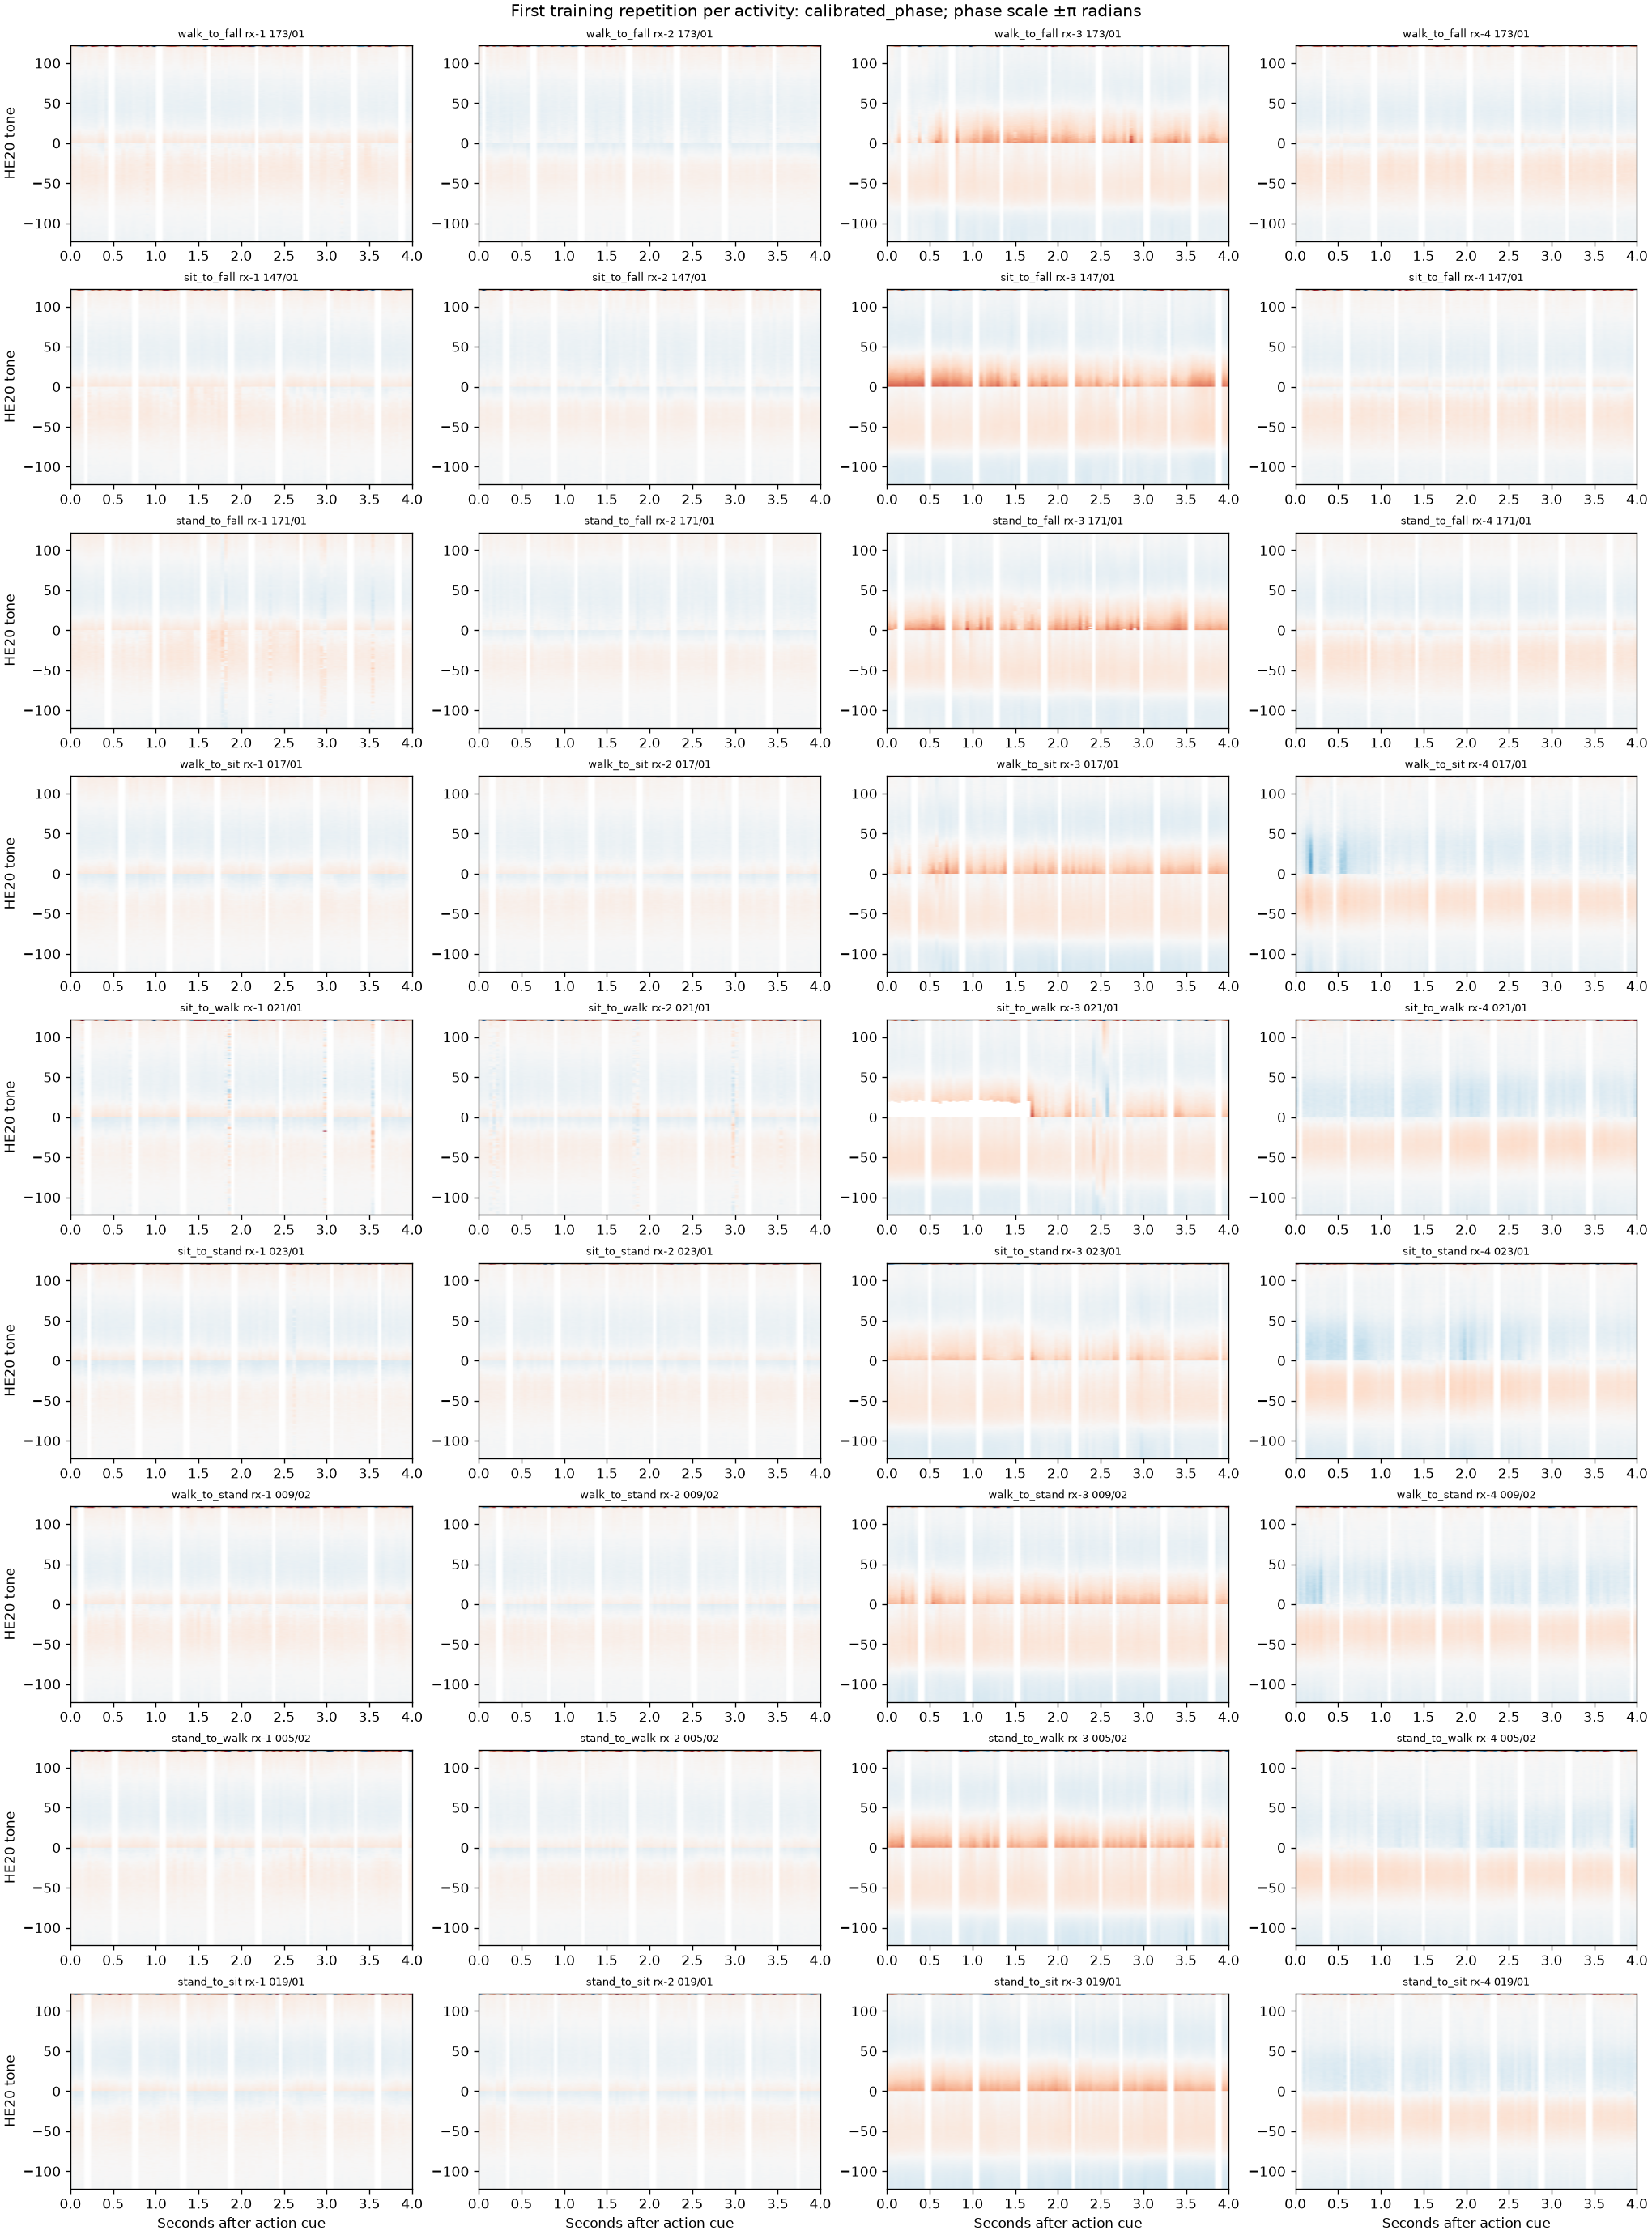

receiver_right,rx-1,rx-2,rx-3,rx-4
receiver_left,,,,
rx-1,1.000000,-0.310881,-0.023319,0.141638
rx-2,-0.310881,1.000000,-0.287419,-0.547963
rx-3,-0.023319,-0.287419,1.000000,0.136588
rx-4,0.141638,-0.547963,0.136588,1.000000


,label,offset_seconds,attempts,median_action_duration_s,fraction_recovery_cue_after_window
2,sit_to_fall,0.0,14,4.466821,0.857143
7,sit_to_stand,0.0,18,4.026552,0.500000
12,sit_to_walk,0.0,20,5.592304,1.000000
17,stand_to_fall,0.0,16,4.122983,0.625000
22,stand_to_sit,0.0,19,4.051667,0.526316
27,stand_to_walk,0.0,4,5.191946,1.000000
32,walk_to_fall,0.0,15,4.990117,0.866667
37,walk_to_sit,0.0,19,5.817192,1.000000
42,walk_to_stand,0.0,3,5.460005,1.000000


In [3]:
display(pd.read_csv(RESULTS / "eda_training_quality.csv").head(20))
show_figure("eda_signal_summary.png")
show_figure("eda_calibrated_phase_examples.png", width=1000)
display(pd.read_csv(RESULTS / "eda_training_receiver_correlations.csv").query("representation == 'amplitude'").pivot(index="receiver_left", columns="receiver_right", values="spearman"))
display(pd.read_csv(RESULTS / "eda_training_window_support.csv").query("offset_seconds == 0"))

## Backward/forward windows

For each attempt and shift δ, the window is `[action cue + δ, action cue + δ + 4 seconds)`. Shifts are −0.50, −0.25, 0, +0.25 and +0.50 seconds. The cue is not a verified fall-impact timestamp.

The fixed scheme trains only at zero shift. The augmented scheme selects one seeded uniform shift per training attempt per epoch. The maximum update count is matched. All validation uses central windows; each scheme selects its representation from five predefined candidates. The three seeds are 17, 29 and 43.

,offset_seconds,window_start_relative_to_cue,window_end_relative_to_cue
0,-0.50,-0.50,3.50
1,-0.25,-0.25,3.75
2,0.00,0.00,4.00
3,0.25,0.25,4.25
4,0.50,0.50,4.50


,scheme,representation,n,accuracy,balanced_accuracy,fall_precision,fall_recall,specificity,fall_f1,roc_auc,average_precision,tn,fp,fn,tp
0,fixed,amplitude,42,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,27,0,0,15
1,fixed,raw_phase,42,0.452381,0.529630,0.375000,0.800000,0.259259,0.510638,0.565432,0.457966,7,20,3,12
2,fixed,calibrated_phase,42,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,27,0,0,15
3,fixed,phase_change,42,0.690476,0.670370,0.562500,0.600000,0.740741,0.580645,0.743210,0.645712,20,7,6,9
4,fixed,phase_change_smoothed,42,0.833333,0.811111,0.785714,0.733333,0.888889,0.758621,0.874074,0.855095,24,3,4,11
5,shift_augmented,amplitude,42,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,27,0,0,15
6,shift_augmented,raw_phase,42,0.666667,0.622222,0.538462,0.466667,0.777778,0.500000,0.669136,0.548908,21,6,8,7
7,shift_augmented,calibrated_phase,42,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,27,0,0,15
8,shift_augmented,phase_change,42,0.714286,0.718519,0.578947,0.733333,0.703704,0.647059,0.817284,0.753153,19,8,4,11
9,shift_augmented,phase_change_smoothed,42,0.785714,0.803704,0.650000,0.866667,0.740741,0.742857,0.874074,0.825925,20,7,2,13


{'selected_by_scheme': {'fixed': 'amplitude', 'shift_augmented': 'amplitude'},
 'winner': {'scheme': 'fixed', 'representation': 'amplitude'},
 'threshold': 0.5,
 'rule': 'Center-window validation ensemble balanced accuracy, then ROC AUC, then config order. Epochs minimize weighted validation BCE. No test selection.',
 'training_seconds': 497.84849258100076,
 'versions': {'numpy': '2.5.4',
  'pandas': '2.3.3',
  'torch': '2.14.1+cpu',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2'}}

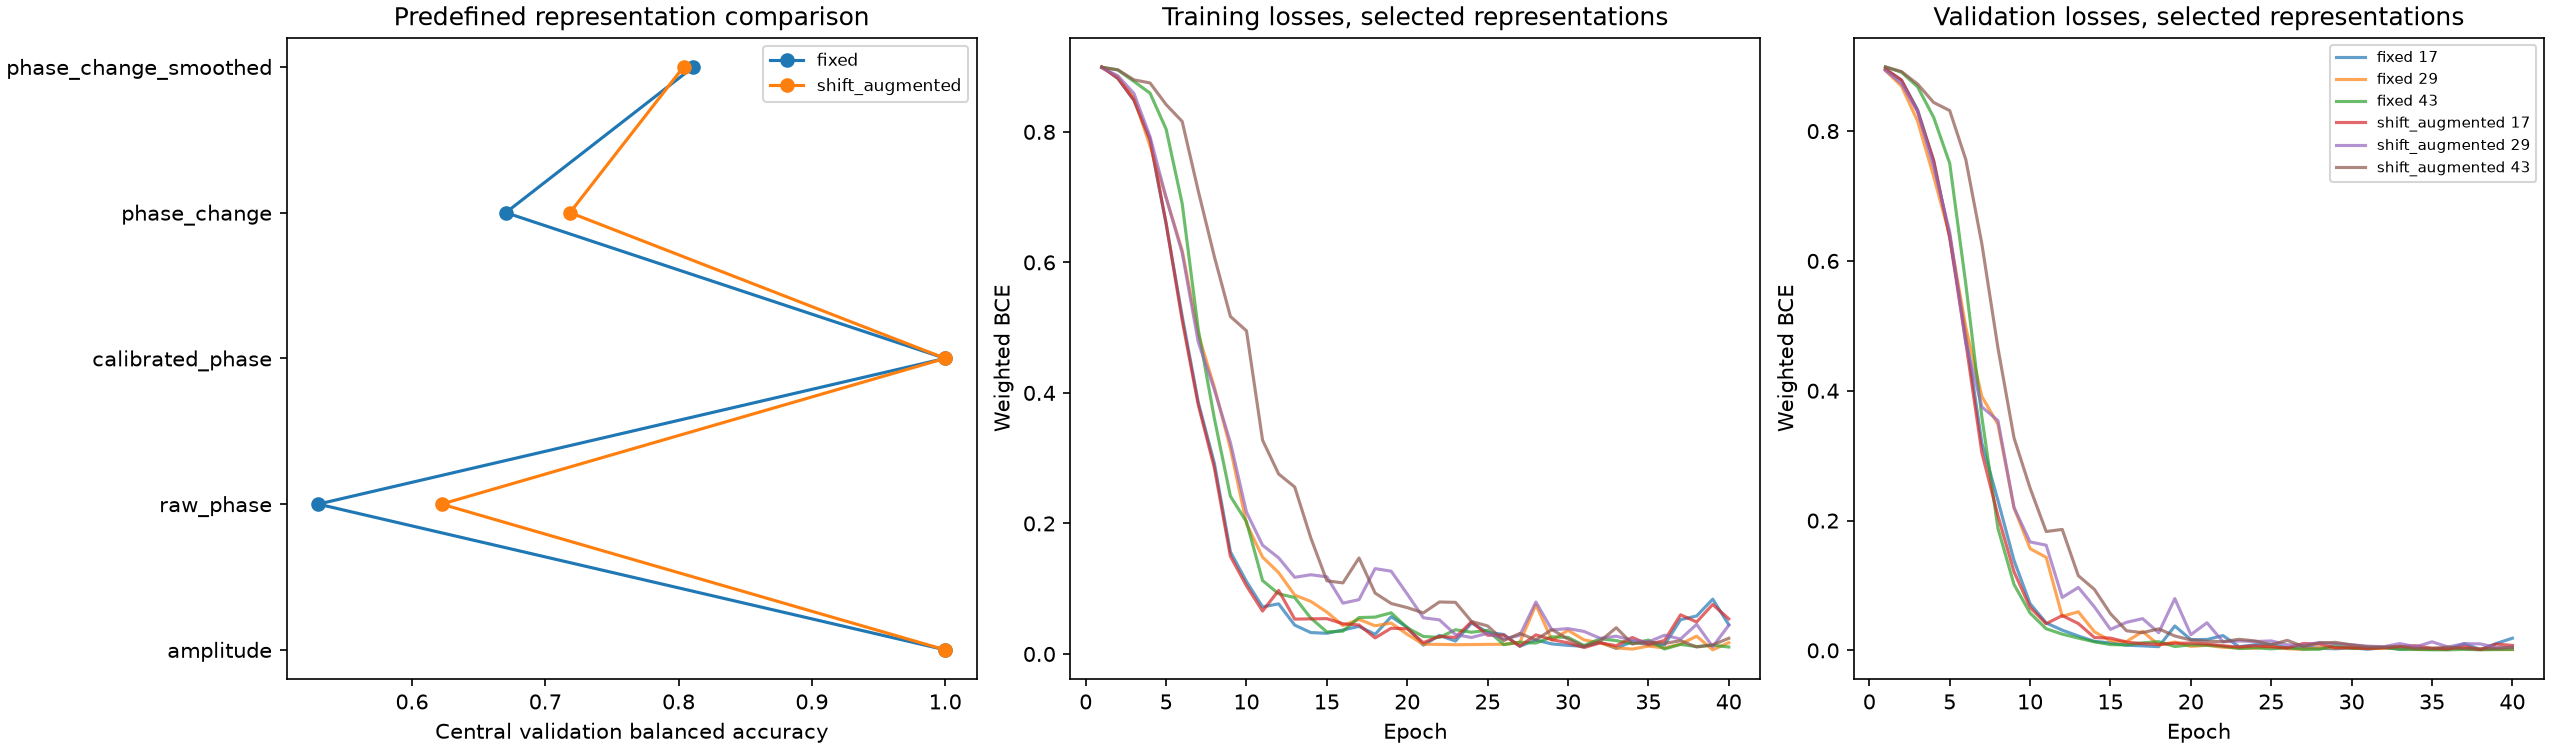

In [4]:
display(pd.DataFrame({"offset_seconds": config["offsets_seconds"], "window_start_relative_to_cue": config["offsets_seconds"], "window_end_relative_to_cue": [x + config["window_seconds"] for x in config["offsets_seconds"]]}))
display(pd.read_csv(RESULTS / "validation_candidates.csv"))
selection = read_json("selection.json")
display({k: selection[k] for k in ["selected_by_scheme", "winner", "threshold", "rule", "training_seconds", "versions"]})
show_figure("training_curves.png")

## Held-out CNN results and controls

Models and thresholds were frozen before test scoring. Each central metric has one prediction per test attempt. Quality-only and collection-order controls probe acquisition and chronology associations. Scenario-cluster confidence intervals condition on this one split/session.

,scheme,representation,offset_seconds,model,n,accuracy,balanced_accuracy,fall_precision,fall_recall,specificity,fall_f1,roc_auc,average_precision,tn,fp,fn,tp
10,fixed,amplitude,0.0,cnn,36,0.972222,0.958333,1.000000,0.916667,1.000000,0.956522,1.000000,1.000000,24,0,1,11
11,fixed,amplitude,0.0,summary_logistic,36,0.944444,0.916667,1.000000,0.833333,1.000000,0.909091,0.989583,0.983333,24,0,2,10
12,fixed,amplitude,0.0,quality_only,36,0.527778,0.520833,0.352941,0.500000,0.541667,0.413793,0.479167,0.356747,13,11,6,6
13,fixed,amplitude,0.0,collection_order,36,0.944444,0.958333,0.857143,1.000000,0.916667,0.923077,1.000000,1.000000,22,2,0,12
14,fixed,amplitude,0.0,majority,36,0.666667,0.500000,0.000000,0.000000,1.000000,0.000000,0.500000,0.333333,24,0,12,0
35,shift_augmented,amplitude,0.0,cnn,36,0.972222,0.958333,1.000000,0.916667,1.000000,0.956522,1.000000,1.000000,24,0,1,11
36,shift_augmented,amplitude,0.0,summary_logistic,36,0.944444,0.916667,1.000000,0.833333,1.000000,0.909091,0.989583,0.983333,24,0,2,10
37,shift_augmented,amplitude,0.0,quality_only,36,0.527778,0.520833,0.352941,0.500000,0.541667,0.413793,0.479167,0.356747,13,11,6,6
38,shift_augmented,amplitude,0.0,collection_order,36,0.944444,0.958333,0.857143,1.000000,0.916667,0.923077,1.000000,1.000000,22,2,0,12
39,shift_augmented,amplitude,0.0,majority,36,0.666667,0.500000,0.000000,0.000000,1.000000,0.000000,0.500000,0.333333,24,0,12,0


{'winner': {'scheme': 'fixed', 'representation': 'amplitude'},
 'selected_by_scheme': {'fixed': 'amplitude', 'shift_augmented': 'amplitude'},
 'center_scenario_bootstrap_95_percent_intervals': {'fixed': {'balanced_accuracy': [0.8636363636363636,
    1.0],
   'fall_recall': [0.7272727272727273, 1.0],
   'specificity': [1.0, 1.0],
   'roc_auc': [0.9999999999999999, 1.0]},
  'shift_augmented': {'balanced_accuracy': [0.8636363636363636, 1.0],
   'fall_recall': [0.7272727272727273, 1.0],
   'specificity': [1.0, 1.0],
   'roc_auc': [0.9999999999999999, 1.0]}},
 'test_attempts': 36,
 'test_scenarios': 21,
 'selection_sha256': 'a7971fc8e0a047894cccc39624687c7a391f54606ff5cfa10e7b23bd395e1a86',
 'bootstrap_seed': 812,
 'bootstrap_repetitions': 2000,
 'scope': 'Within one participant/session. Five offsets are correlated sensitivity measurements, not five independent test sets. Models selected before any test scoring.'}

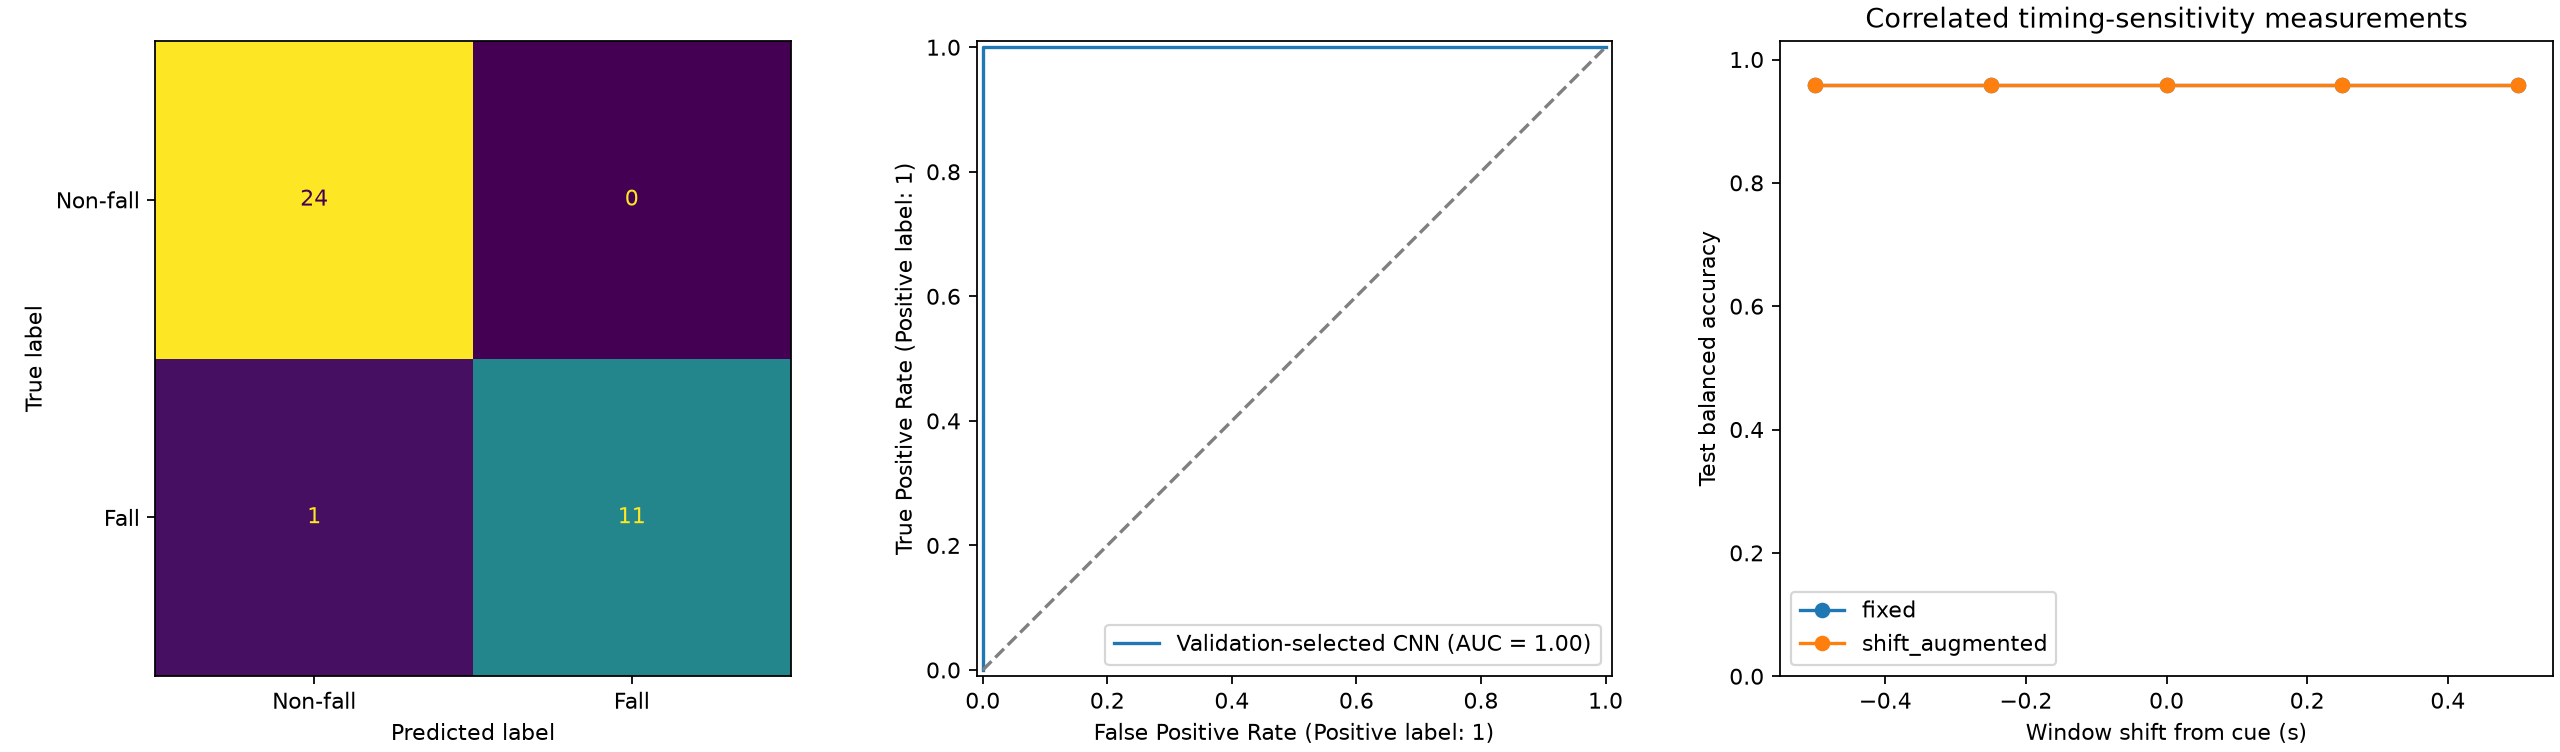

In [5]:
scores = pd.read_csv(RESULTS / "test_metrics.csv")
display(scores.loc[scores.offset_seconds.eq(0)])
display(read_json("evaluation.json"))
show_figure("test_evaluation.png")

## Sensitivity to window alignment

The same frozen models see all five test offsets. These are correlated measurements of the same test attempts, not a larger independent cohort. A separately selected representation for each scheme makes this a comparison of selected pipelines rather than an isolated causal estimate of augmentation.

In [6]:
display(scores.loc[scores.model.eq("cnn")])
stability = pd.read_csv(RESULTS / "timing_stability.csv")
display(stability.groupby("scheme").prediction_changes.agg(["count", lambda x: (x > 1).sum()]))
display(pd.read_csv(RESULTS / "test_activity_metrics.csv").query("offset_seconds == 0"))

,scheme,representation,offset_seconds,model,n,accuracy,balanced_accuracy,fall_precision,fall_recall,specificity,fall_f1,roc_auc,average_precision,tn,fp,fn,tp
0,fixed,amplitude,-0.50,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
5,fixed,amplitude,-0.25,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
10,fixed,amplitude,0.00,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
15,fixed,amplitude,0.25,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
20,fixed,amplitude,0.50,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
25,shift_augmented,amplitude,-0.50,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
30,shift_augmented,amplitude,-0.25,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
35,shift_augmented,amplitude,0.00,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
40,shift_augmented,amplitude,0.25,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11
45,shift_augmented,amplitude,0.50,cnn,36,0.972222,0.958333,1.0,0.916667,1.0,0.956522,1.0,1.0,24,0,1,11


,count,<lambda_0>
scheme,,
fixed,36,0
shift_augmented,36,0


,scheme,offset_seconds,activity,n,accuracy,balanced_accuracy,fall_precision,fall_recall,specificity,fall_f1,roc_auc,average_precision,tn,fp,fn,tp
18,fixed,0.0,sit_to_fall,3,1.0,1.0,1.0,1.0,NaN,1.000000,NaN,1.0,0,0,0,3
19,fixed,0.0,sit_to_stand,4,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,4,0,0,0
20,fixed,0.0,sit_to_walk,5,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,5,0,0,0
21,fixed,0.0,stand_to_fall,5,0.8,0.8,1.0,0.8,NaN,0.888889,NaN,1.0,0,0,1,4
22,fixed,0.0,stand_to_sit,6,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,6,0,0,0
23,fixed,0.0,stand_to_walk,2,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,2,0,0,0
24,fixed,0.0,walk_to_fall,4,1.0,1.0,1.0,1.0,NaN,1.000000,NaN,1.0,0,0,0,4
25,fixed,0.0,walk_to_sit,5,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,5,0,0,0
26,fixed,0.0,walk_to_stand,2,1.0,1.0,0.0,0.0,1.0,0.000000,NaN,NaN,2,0,0,0
63,shift_augmented,0.0,sit_to_fall,3,1.0,1.0,1.0,1.0,NaN,1.000000,NaN,1.0,0,0,0,3


## Scope and reproducibility

This session has one participant and nine scripted activities. Shared recording time, equipment, receiver placement and environment can contribute to classification even with scenario grouping. Results do not establish continuous fall detection or performance on new people/sessions. The test set has now been inspected.

`manifest.json` records source/configuration/split/array/code hashes; `selection.json` records checkpoint hashes and selection. Raw data were read without modification. Large arrays and CPU checkpoints stay in ignored artifacts. [Read the complete report](results/four_rx_v1/REPORT.md) for methods, measurements and limitations.